# Where Gemma picks BFS or DFS: the single-token fork

**Artifact:** experiment 31 of the AI-Inventor run *"prompt bans substitute, not just subtract"* (claim S, `method.py`). **Model:** `google/gemma-3-4b-it` (bf16, sampled at temperature 1.0, top-p 1.0, no top-k).

Asked the same grid-path task 200 times (prompt **T1**: *write `solve(grid, start, goal)` that returns a path between two grid cells*), Gemma writes **depth-first search (DFS) in about 70%** of the programs and **breadth-first search (BFS) in about 30%**. The research behind this artifact asks whether a model's choice between possible solutions is a variable you can find and steer inside the model. This notebook covers the first step: **where in a generation is the BFS-or-DFS choice made?**

The method is **prefix resampling** (stage S4, `stage_fork` in `method.py`):

1. Take a finished BFS or DFS program (a *base path*) and keep only its first *t* response tokens.
2. Let the model write 8 fresh continuations from that prefix (same prompt, temperature 1).
3. Label every continuation BFS / DFS / other with a lexical *partial-code labeller*.
4. Follow P(own class | first t tokens) as t grows. A significant jump (a *change point*) marks where the plan was fixed. A single-token rescan around the jump finds the token that fixed it.

**What runs here.** The CPU part of `stage_fork` and its helpers from `src/fork.py` run unchanged on the outputs Gemma produced on a GPU in the full run: 100 of the 200 T1 samples and all 3,712 prefix-resampling continuations. Sampling those continuations needs the 4B model on a GPU, so the one step that generated them now reads the cached continuation of each requested prefix. Everything after that (labelling, change points, the fork-index rule, the token table) is the original code. The GPU stages that build on this fork (SAE readout and steering) are summarised at the end.

**Full-run result to compare with.** All 12 BFS base paths have a significant change point, and the plan is **one token at response index 32**. That token comes right after a 32-token opening that 89% of the programs share: the code fence, `def solve(grid, start, goal):`, `rows = len(grid)`, `cols = len(grid[0])` and an indent. If the token is `visited`, the program becomes DFS (P(BFS) ≈ 0.01). If it is a blank line, `if` or `queue`, it becomes BFS (P(BFS) 0.95–1.0). This happens about **138 tokens before** any code identifies the algorithm.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py's import block (argparse/gc/os kept as in the script) + what src/cfg.py, src/fork.py and src/figures_S.py
# import. torch, transformers and the GPU modules (engine, gen, prompts, sae) are not needed for the CPU part of S4.
import argparse
import gc
import hashlib
import itertools
import json
import math
import os
import re
import sys
import time
from collections import Counter
from pathlib import Path
from types import SimpleNamespace
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
from loguru import logger

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-6/experiment-31/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
print(data["metadata"]["title"])
print(f"{len(EXAMPLES)} T1 samples, {data['metadata']['n_fork_continuations']} cached fork continuations")
print("subset:", data["metadata"]["subset_rule"])
print("\nT1 prompt (template W1):\n" + EXAMPLES[0]["input"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Where Gemma picks BFS or DFS: demo subset for the S4 fork analysis
100 T1 samples, 3712 cached fork continuations
subset: 20 T1 samples per template W1-W5 (BFS share of the template kept), all 24 fork base paths included, filled with the lowest-slot remaining samples of each class

T1 prompt (template W1):
Do not use house for this task. . . . . . .

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and eve

## Configuration

The three knobs that set how much of the stage-S4 analysis runs. They are set to the full-run values: on a CPU the whole stage takes seconds, and the demo data holds the cached continuations of all 24 base paths. Smaller values give a coarser run. With fewer base paths the fork-index rule has fewer candidates: with 1 path per class it lands on the one BFS path's early fork (index 14) rather than 32. With fewer permutations the change-point p-values are coarser. The smallest possible p is 1/(FORK_PERM + 1), so FORK_PERM must be at least 20 for any p < 0.05.

In [5]:
# ---- tunable parameters of stage S4: the full-run values (the whole notebook runs in well under a minute on CPU)
N_BASE_PER_CLASS = 12   # base paths per class (BFS, DFS) to resample; full run 12 (stage_fork: pick(cls), n_want=12)
REFINE_PATHS = 8        # paths refined at single-token resolution; full run 8 (method.py --refine-paths 8)
FORK_PERM = 1000        # permutations of the change-point null; full run 1000 (cfg.FORK_PERM)
# quicker, coarser settings tested along the way: (1, 1, 20) and (3, 2, 100)

## Constants and utilities from `src/cfg.py`

These are the S4 design constants of the full run: the five prompt templates W1–W5, the coarse scan positions t ∈ {0, 4, …, 60}, 8 continuations per prefix (16 in the refinement), the 320-token labeller horizon, the minimum rise of 0.4, and the 0.8 / 0.2 thresholds of the BFS and DFS token sets. They are fixed because the cached continuations were generated with them.

The T1 prompt is the neutral *twin* of a ban prompt: template W1 gives *"Do not use house for this task."*, then dot padding to the length of the matching ban sentence, then the task text. The ban side (`{X}` = an algorithm name) belongs to other stages. Also copied here: `stable_seed` (deterministic seeds from strings), `wilson_ci` and `write_json`. Results go to `results/` and figures to `figures/`, as in the script.

In [6]:
# ---- from src/cfg.py: prompt templates and the S4 design (fixed: the cached continuations were generated with these)
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim (ban side: length only)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
FORK_POSITIONS = tuple(range(0, 61, 4))    # coarse scan t in {0, 4, ..., 60}
FORK_CONT = 8                              # continuations per (path, t)
FORK_REFINE_CONT = 16
FORK_MAX_NEW = 320                         # partial-code labeller horizon
FORK_RISE = 0.4
TOKEN_SET_HI = 0.8                         # B = fork tokens with P(BFS | tok) >= 0.8
TOKEN_SET_LO = 0.2                         # D = fork tokens with P(BFS | tok) <= 0.2
DATA_DIR = Path("data")                    # rows are served from mini_demo_data.json (see read_jsonl below)
RESULTS_DIR = Path("results")
FIG_DIR = Path("figures")
for _d in (RESULTS_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # (the script also adds a rotating file sink LOG_DIR / f"{name}.log")


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp23 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


setup_logging("method_fork")

## Partial-code labeller, change points and prefix bookkeeping (`src/fork.py`)

- **`partial_label(text)`** labels a program *prefix* by its first decisive lexical evidence. BFS evidence is `.popleft()`, `.pop(0)`, `.get()`, `queue.Queue()` or `SimpleQueue()`. DFS evidence is `stack.pop()`, `LifoQueue()`, or a nested function that calls itself. Heap calls (`heappush`, `heappop`, `PriorityQueue`) mean "other" (Dijkstra, A*). It returns `None` while the prefix is still undecided. The continuations were sampled only until the labeller decided, for at most 320 tokens.
- **`change_points(k, n)`** finds the best binomial segmentation of a series of k-of-n counts into up to three segments, with a BIC-style penalty on a second change point. Its p-value comes from a null that permutes the positions.
- **`canonical_prefix`, `token_table`, `identical_prefix_share` and `lcp`** do the prefix bookkeeping: the most common opening c*, the class split per next token after it, the share of sample pairs that share their first t tokens, and the longest common prefix of two programs.

`method.py` imports this module as `import fork as F`; the `F` namespace at the end of the cell keeps those calls unchanged.

In [7]:
BFS_RE = re.compile(r"\.popleft\s*\(|\.pop\s*\(\s*0\s*\)|\.get\s*\(\s*\)\s*$|\bqueue\.Queue\s*\(|\bSimpleQueue\s*\(", re.M)
STACK_RE = re.compile(r"\b(\w*stack\w*)\s*\.\s*pop\s*\(\s*\)|LifoQueue\s*\(", re.I)
HEAP_RE = re.compile(r"\bheappush\s*\(|\bheappop\s*\(|\bPriorityQueue\s*\(")
DEF_RE = re.compile(r"^([ \t]*)def\s+(\w+)\s*\(", re.M)


def _code(text: str) -> str:
    i = text.find("```")
    if i >= 0:
        j = text.find("\n", i)
        text = text[j + 1:] if j >= 0 else ""
    k = text.find("```")
    return text[:k] if k >= 0 else text


def recursion_pos(code: str) -> int | None:
    """Char position of the first self-call inside the body of a nested def (partial text allowed)."""
    best = None
    for m in DEF_RE.finditer(code):
        ind = len(m.group(1).expandtabs(4))
        name = m.group(2)
        if name == "solve" and ind == 0:
            continue
        body_start = code.find("\n", m.end())
        if body_start < 0:
            continue
        pos = body_start + 1
        for line in code[body_start + 1:].split("\n"):
            stripped = line.strip()
            if stripped:
                li = len(line) - len(line.lstrip())
                if li <= ind:
                    break
                mm = re.search(r"(?<![\w.])" + re.escape(name) + r"\s*\(", line)
                if mm and not stripped.startswith("def "):
                    cand = pos + mm.start()
                    best = cand if best is None else min(best, cand)
                    break
            pos += len(line) + 1
    return best


def evidence(text: str) -> dict[str, int | None]:
    code = _code(text)
    out: dict[str, int | None] = {}
    m = BFS_RE.search(code)
    out["bfs"] = m.start() if m else None
    m = STACK_RE.search(code)
    st = m.start() if m else None
    rc = recursion_pos(code)
    out["dfs"] = min([x for x in (st, rc) if x is not None], default=None)
    m = HEAP_RE.search(code)
    out["other"] = m.start() if m else None
    return out


def partial_label(text: str) -> str | None:
    """'bfs' | 'dfs' | 'other' at the first decisive evidence in the program prefix; None while undecided."""
    ev = evidence(text)
    cands = [(v, k) for k, v in ev.items() if v is not None]
    if not cands:
        return None
    return min(cands)[1]


def decided(text: str) -> bool:
    return partial_label(text) is not None


def map_full(label: str) -> str:
    return label if label in ("bfs", "dfs") else "other"


# ------------------------------------------------------------------------------------------------ change points
def best_segmentation(k: np.ndarray, n: np.ndarray, max_cp: int = 2) -> tuple[float, list[int]]:
    """Exhaustive binomial segmentation with up to max_cp change points (prefix sums); returns (log-likelihood gain
    over no change, minus a BIC-style 1.5 log N penalty per change point beyond the first, cps); cp = index i means a
    change between positions i-1 and i."""
    T = len(k)
    ck = [0.0]
    cn = [0.0]
    for a, b in zip(k, n):
        ck.append(ck[-1] + float(a))
        cn.append(cn[-1] + float(b))

    def ll(i: int, j: int) -> float:
        K, N = ck[j] - ck[i], cn[j] - cn[i]
        if N <= 0 or K <= 0 or K >= N:
            return 0.0
        p = K / N
        return K * math.log(p) + (N - K) * math.log(1 - p)
    base = ll(0, T)
    pen = 1.5 * math.log(max(cn[-1], 2.0))
    best = (0.0, [])
    for i in range(1, T):
        g = ll(0, i) + ll(i, T) - base
        if g > best[0] + 1e-12:
            best = (g, [i])
    if max_cp >= 2:
        for i in range(1, T - 1):
            li = ll(0, i)
            for j in range(i + 1, T):
                g = li + ll(i, j) + ll(j, T) - base - pen
                if g > best[0] + 1e-12:
                    best = (g, [i, j])
    return best


def change_points(k: list[int], n: list[int], n_perm: int = 1000, seed: int = 0) -> dict[str, Any]:
    k_a, n_a = np.asarray(k, float), np.asarray(n, float)
    gain, cps = best_segmentation(k_a, n_a)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        o = rng.permutation(len(k_a))
        null.append(best_segmentation(k_a[o], n_a[o])[0])
    p = (1 + sum(g >= gain for g in null)) / (1 + n_perm)
    segs = []
    b = [0, *cps, len(k_a)]
    for i in range(len(b) - 1):
        kk, nn = k_a[b[i]:b[i + 1]].sum(), n_a[b[i]:b[i + 1]].sum()
        segs.append({"start_idx": b[i], "end_idx": b[i + 1], "p": float(kk / nn) if nn else None})
    return {"gain": gain, "cps": cps, "p_value": p, "segments": segs}


# ------------------------------------------------------------------------------------------------ prefixes
def lcp(a: list[int], b: list[int]) -> int:
    n = 0
    for x, y in zip(a, b):
        if x != y:
            break
        n += 1
    return n


def identical_prefix_share(ids_by_template: dict[str, list[list[int]]], t: int) -> dict[str, float]:
    out = {}
    for w, L in ids_by_template.items():
        pairs = list(itertools.combinations(range(len(L)), 2))
        same = sum(1 for i, j in pairs if len(L[i]) >= t and len(L[j]) >= t and L[i][:t] == L[j][:t])
        out[w] = same / len(pairs) if pairs else float("nan")
    return out


def canonical_prefix(ids: list[list[int]], t: int) -> tuple[list[int], int]:
    c = Counter(tuple(x[:t]) for x in ids if len(x) >= t)
    pref, cnt = c.most_common(1)[0]
    return list(pref), cnt


def token_table(rows: list[dict[str, Any]], cstar: list[int], min_n: int = 3) -> dict[int, dict[str, Any]]:
    """rows: {ids (response), cls ('bfs'|'dfs'|'other')}; tokens right after c* among rows whose prefix is c*."""
    t = len(cstar)
    by: dict[int, list[str]] = {}
    for r in rows:
        ids = r["ids"]
        if len(ids) > t and ids[:t] == cstar:
            by.setdefault(int(ids[t]), []).append(r["cls"])
    out = {}
    for tok, cl in by.items():
        n_bd = sum(c in ("bfs", "dfs") for c in cl)
        out[tok] = {"n": len(cl), "n_bfs": sum(c == "bfs" for c in cl), "n_dfs": sum(c == "dfs" for c in cl),
                    "p_bfs": (sum(c == "bfs" for c in cl) / n_bd) if n_bd else None, "pooled": len(cl) < min_n}
    return out


# method.py uses these helpers as `import fork as F`
F = SimpleNamespace(partial_label=partial_label, decided=decided, map_full=map_full, change_points=change_points,
                    lcp=lcp, identical_prefix_share=identical_prefix_share, canonical_prefix=canonical_prefix,
                    token_table=token_table)

## Tokenizer stand-in and data access

`stage_fork` calls `tok.decode(...)` (the gemma-3-4b-it tokenizer) to turn response token ids back into program text. That Hugging Face repo is gated, so the demo data carries the decoded piece of each token id it uses (160 distinct ids: the programs are very stereotyped). Gemma 3's decoder only replaces `▁` with a space, applies byte fallback and fuses the pieces, with no clean-up step. Joining the pieces is therefore exactly the tokenizer's decode, and the cell checks this against the stored text of every sample. `read_jsonl` stands in for reading `data/raw_s3.jsonl` (generations) and `data/labels.jsonl` (labels) from disk.

In [8]:
class MiniTok:
    """tok.decode of the gemma-3-4b-it tokenizer for the token ids in mini_demo_data.json: Gemma 3's decoder is
    Replace('▁' -> ' '), ByteFallback, Fuse (no clean-up), i.e. a join of the stored pieces."""
    BYTE = re.compile(r"^<0x([0-9A-F]{2})>$")

    def __init__(self, vocab: dict[str, str], special_ids: list[int]):
        self.pieces = {int(i): p for i, p in vocab.items()}
        self.special = set(special_ids)

    def decode(self, ids: list[int], skip_special_tokens: bool = False) -> str:
        out, buf = [], b""
        for i in ids:
            if skip_special_tokens and i in self.special:
                continue
            m = self.BYTE.match(self.pieces[i])
            if m:                                  # byte-fallback token: collect the bytes, decode them as UTF-8
                buf += bytes([int(m.group(1), 16)])
                continue
            if buf:
                out.append(buf.decode("utf-8", errors="replace"))
                buf = b""
            out.append(self.pieces[i])
        return "".join(out) + (buf.decode("utf-8", errors="replace") if buf else "")


tok = MiniTok(data["metadata"]["vocab"], data["metadata"]["special_ids"])
n_same = sum(tok.decode(ex["raw_row"]["token_ids"], skip_special_tokens=True) == ex["raw_row"]["text"] for ex in EXAMPLES)
print(f"tok.decode reproduces the stored text of {n_same}/{len(EXAMPLES)} samples")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    """Stands in for cfg.read_jsonl(DATA_DIR / name): the rows of that file that are in mini_demo_data.json."""
    name = Path(p).name
    if name == "raw_s3.jsonl":
        return [dict(ex["raw_row"]) for ex in EXAMPLES]
    if name == "labels.jsonl":
        return [dict(ex["label_row"]) for ex in EXAMPLES]
    raise FileNotFoundError(f"{name} is not part of the demo data")

tok.decode reproduces the stored text of 100/100 samples


## Row helpers from `method.py`

`load_labelled` joins each generation row with its label row. The labels come from the frozen labellers of earlier iterations: `label` (bfs / dfs / …, from runtime tracing and AST rules, with an LLM judge on disagreements), `passed` (the hidden tests) and `valid`. `response_ids` strips the trailing stop token. `identifying_index` binary-searches for the first response token at which the partial labeller is decided, i.e. where the program text first reveals its algorithm.

In [9]:
def load_labelled(raw_name: str, task: str | None = None, arm: str | None = None) -> list[dict[str, Any]]:
    """raw rows joined with their label rows (rows without a label are skipped)."""
    lab = {r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")}
    out = []
    for r in read_jsonl(DATA_DIR / raw_name):
        if task and r.get("task") != task:
            continue
        if arm and r.get("arm") != arm:
            continue
        L = lab.get(r["row_id"])
        if L is None:
            continue
        rr = dict(r)
        for k in ("label", "labeller_source", "passed", "valid", "runtime_label", "ast_label", "judge_label",
                  "fallback_label", "code_sha256", "code", "extract_how"):
            rr[k] = L.get(k)
        out.append(rr)
    return out


def response_ids(r: dict[str, Any]) -> list[int]:
    """generated ids without the trailing stop token."""
    ids = list(r["token_ids"])
    while ids and ids[-1] in (1, 106):
        ids = ids[:-1]
    return ids


def identifying_index(tok: Any, ids: list[int]) -> int | None:
    """First response-token index i such that the partial labeller is decided on ids[:i+1] (binary search)."""
    if F.partial_label(tok.decode(ids, skip_special_tokens=True)) is None:
        return None
    lo, hi = 0, len(ids) - 1
    while lo < hi:
        mid = (lo + hi) // 2
        if F.partial_label(tok.decode(ids[:mid + 1], skip_special_tokens=True)) is not None:
            hi = mid
        else:
            lo = mid + 1
    return lo

## 1. Behaviour: which algorithm does Gemma write? (stage S3, natural split)

The first, behavioural question: for one fixed prompt, how often does the model write each algorithm? `composition` (from `src/analysis_S.py`) counts attempted and correct programs per class, with Wilson 95% intervals. It also reports the rarefied Hill-1 diversity of the correct programs (the effective number of algorithms), and calls a class the *default* when it makes up at least 60% of the correct programs. The full run has 200 samples (5 templates × 40 sampling slots); this demo uses 100 of them, keeping each template's BFS share.

In [10]:
# ---- from src/analysis_S.py
NC = ("invalid", "disputed")


def hill1_rarefied(labels: list[str], depth: int = 25, n_draw: int = 500, seed: int = 0) -> dict[str, Any]:
    if not labels:
        return {"hill1": None, "n": 0, "flag_below_depth": True}
    rng = np.random.default_rng(seed)
    if len(labels) < depth:
        c = Counter(labels)
        p = np.array(list(c.values())) / len(labels)
        return {"hill1": float(np.exp(-(p * np.log(p)).sum())), "n": len(labels), "flag_below_depth": True}
    arr = np.array(labels)
    vals = []
    for _ in range(n_draw):
        s = rng.choice(arr, size=depth, replace=False)
        c = Counter(s.tolist())
        p = np.array(list(c.values())) / depth
        vals.append(np.exp(-(p * np.log(p)).sum()))
    return {"hill1": float(np.mean(vals)), "n": len(labels), "flag_below_depth": False}


def composition(rows: list[dict[str, Any]], target: str | None = None) -> dict[str, Any]:
    n = len(rows)
    att = Counter(r["label"] for r in rows)
    corr = Counter(r["label"] for r in rows if r.get("passed") and r["label"] not in NC)
    n_valid_att = sum(v for k, v in att.items() if k not in NC)
    out = {"n": n, "attempted": dict(att), "correct": dict(corr), "n_attempted_valid": n_valid_att,
           "pass_rate": sum(1 for r in rows if r.get("passed")) / max(n, 1),
           "pass_ci": wilson_ci(sum(1 for r in rows if r.get("passed")), n),
           "invalid": att.get("invalid", 0), "disputed": att.get("disputed", 0), "other": att.get("other", 0),
           "hill1_correct": hill1_rarefied([r["label"] for r in rows if r.get("passed") and r["label"] not in NC])}
    shares = {}
    for k, v in att.items():
        if k in NC:
            continue
        lo, hi = wilson_ci(v, n_valid_att)
        shares[k] = {"k": v, "share": v / max(n_valid_att, 1), "ci": [lo, hi]}
    out["attempt_shares"] = shares
    nc = sum(corr.values())
    if nc:
        top, kk = corr.most_common(1)[0]
        out["default"] = top if kk / nc >= 0.6 else "NO DEFAULT"
        out["default_share"] = kk / nc
    if target:
        k = sum(1 for r in rows if r["label"] == target and r.get("passed"))
        out["target_correct"] = k
        out["target_correct_ci"] = wilson_ci(k, n)
        out["target_attempted"] = att.get(target, 0)
    return out


def natural_split(load_labelled) -> dict[str, Any]:
    res = {}
    for task in ("T1",):      # the script: ("T1", "T04", "R6"); the demo data holds the T1 samples only
        rows = [r for r in load_labelled("raw_s3.jsonl", task) if r["arm"] == "twin"]
        res[task] = {"all": composition(rows), "by_template": {w: composition([r for r in rows if r["template"] == w])
                                                               for w in TEMPLATE_IDS}}
    write_json(RESULTS_DIR / "natural_split.json", res)
    return res


nsplit = natural_split(load_labelled)
comp_t1 = nsplit["T1"]["all"]
print(f"T1, {comp_t1['n']} samples: attempted {comp_t1['attempted']}, correct {comp_t1['correct']}, pass rate "
      f"{comp_t1['pass_rate']:.2f} [{comp_t1['pass_ci'][0]:.2f}, {comp_t1['pass_ci'][1]:.2f}], default "
      f"{comp_t1.get('default')} ({comp_t1.get('default_share', 0):.2f} of correct), "
      f"Hill-1 of correct {comp_t1['hill1_correct']['hill1']:.2f}")
for k, s in comp_t1["attempt_shares"].items():
    print(f"  attempted {k}: {s['k']} = {s['share']:.2f} [{s['ci'][0]:.2f}, {s['ci'][1]:.2f}]")
for w, c in nsplit["T1"]["by_template"].items():
    print(f"  {w} ({TEMPLATES[w][1].format(N='house')}): attempted {c['attempted']}, pass rate {c['pass_rate']:.2f}")

T1, 100 samples: attempted {'dfs': 69, 'bfs': 31}, correct {'dfs': 66, 'bfs': 20}, pass rate 0.86 [0.78, 0.91], default dfs (0.77 of correct), Hill-1 of correct 1.71
  attempted dfs: 69 = 0.69 [0.59, 0.77]
  attempted bfs: 31 = 0.31 [0.23, 0.41]
  W1 (Do not use house for this task.): attempted {'dfs': 17, 'bfs': 3}, pass rate 1.00
  W2 (Your solution must not rely on house.): attempted {'bfs': 9, 'dfs': 11}, pass rate 0.80
  W3 (Avoid house entirely.): attempted {'bfs': 9, 'dfs': 11}, pass rate 0.80
  W4 (house is not allowed here.): attempted {'dfs': 14, 'bfs': 6}, pass rate 0.95
  W5 (Write a correct solution that does not use house.): attempted {'bfs': 4, 'dfs': 16}, pass rate 0.75


## 2. Stage S4, unit test U8: is the partial labeller good enough?

From here on the notebook follows `stage_fork` in `method.py`. The continuations stop as soon as the partial labeller decides, so it has to agree with the full labeller. U8 runs it on the first 320 tokens of every valid sample and passes at an agreement of at least 0.95. If U8 had failed, the GPU run would have generated full-length continuations instead.

In [11]:
# ---- stage_fork (method.py), CPU part: `rows` = the T1 natural-split samples (twin prompt)
rows = [r for r in load_labelled("raw_s3.jsonl", "T1") if r["arm"] == "twin"]
# ---------------- U8: partial labeller vs full labels on valid attempts (first 320 tokens)
conf: dict[str, int] = {}
agree = n = 0
for r in rows:
    if not r["valid"] or r["label"] in ("invalid", "disputed"):
        continue
    pl = F.partial_label(tok.decode(response_ids(r)[:FORK_MAX_NEW], skip_special_tokens=True)) or "other"
    fl = F.map_full(r["label"])
    conf[f"{fl}->{pl}"] = conf.get(f"{fl}->{pl}", 0) + 1
    n += 1
    agree += pl == fl
u8 = {"n": n, "agreement": agree / max(n, 1), "confusion": conf, "pass": agree / max(n, 1) >= 0.95}
use_partial = u8["pass"]
logger.info(f"U8 partial labeller: {u8}")

09:18:18|INFO   |U8 partial labeller: {'n': 100, 'agreement': 1.0, 'confusion': {'dfs->dfs': 69, 'bfs->bfs': 31}, 'pass': True}


## 3. Where does the text reveal the algorithm?

For every sample, `identifying_index` finds the first response token after which the program prefix gets a label: the earliest point at which a reader of the code could tell BFS from DFS. For BFS this is inside the `.popleft()` / `.pop(0)` call that takes from the queue. For DFS it is the recursive call (or a `stack.pop()`). The fork found below is compared with this position.

In [12]:
# ---------------- identifying token per S3 sample
ident = {}
for r in rows:
    ids = response_ids(r)
    i = identifying_index(tok, ids)
    ident[r["row_id"]] = {"idx": i, "token": tok.decode([ids[i]]) if i is not None else None,
                          "cls": F.map_full(r["label"]) if r["valid"] else "invalid", "template": r["template"],
                          "label": r["label"], "passed": r["passed"]}
for cls in ("bfs", "dfs"):
    ix = [v["idx"] for v in ident.values() if v["cls"] == cls and v["idx"] is not None]
    top = Counter(v["token"] for v in ident.values() if v["cls"] == cls and v["idx"] is not None).most_common(3)
    print(f"{cls}: identifying index median {np.median(ix):.0f} (q10 {np.quantile(ix, 0.1):.0f}, "
          f"q90 {np.quantile(ix, 0.9):.0f}), commonest identifying tokens {top}")

bfs: identifying index median 114 (q10 66, q90 161), commonest identifying tokens [(')', 31)]
dfs: identifying index median 203 (q10 169, q90 213), commonest identifying tokens [('(', 66), ('((', 3)]


## 4. Base paths and the coarse prefix scan

`pick` takes `N_BASE_PER_CLASS` valid BFS and DFS samples as base paths: correct programs first, round-robin over the five templates. `items_for` lists the generation requests. For every base path and prefix length t ∈ {0, 4, …, 60}, it asks for 8 continuations of *prompt + the path's first t response tokens*, each with its own common-random-number key (`ukey`).

In the GPU run, `run.run_multi` sampled these from gemma-3-4b-it, stopping each one once the partial labeller decided. Here `run_multi_cached` appends the cached continuation of each requested item instead: the same rows the GPU run wrote to `data/fork_cont.jsonl`. As in the script, only requests that are not done yet are sent.

In [13]:
# ---------------- base paths: 12 BFS + 12 DFS valid attempts (round-robin over templates, prefer correct)
def pick(cls: str, n_want: int = 12) -> list[dict[str, Any]]:
    cand = [r for r in rows if r["valid"] and r["label"] == cls]
    by_w: dict[str, list] = {}
    for r in sorted(cand, key=lambda r: (not r["passed"], r["template"], r["slot"])):
        by_w.setdefault(r["template"], []).append(r)
    out: list[dict[str, Any]] = []
    while len(out) < n_want and any(by_w.values()):
        for w in TEMPLATE_IDS:
            if by_w.get(w) and len(out) < n_want:
                out.append(by_w[w].pop(0))
    return out
base = pick("bfs", N_BASE_PER_CLASS) + pick("dfs", N_BASE_PER_CLASS)
stop = F.decided if use_partial else None          # the GPU run's stop rule and horizon for the continuations
max_new = FORK_MAX_NEW if use_partial else 1536


def items_for(paths: list[dict], positions: list[int], n_cont: int, tag: str) -> list[dict[str, Any]]:
    its = []
    for r in paths:
        ids = response_ids(r)
        for t in positions:
            if t > len(ids):
                continue
            for j in range(n_cont):
                # (the script also stores the model input "ids": twin prompt ids + ids[:t])
                its.append({"row_id": f"{tag}|{r['row_id']}|{t}|{j}",
                            "n_prefix": 0, "prefix_ids": ids[:t], "ukey": ("iter6S-fork", tag, r["row_id"], t, j),
                            "meta": {"task": "T1", "base_row": r["row_id"], "base_label": r["label"], "t": t,
                                     "j": j, "template": r["template"], "tag": tag}})
    return its


CACHED_FORK = {c["row_id"]: c for ex in EXAMPLES for c in ex["fork_continuations"]}
raw_fork: list[dict[str, Any]] = []                # stands in for data/fork_cont.jsonl


def run_multi_cached(items: list[dict[str, Any]], batch_tag: str) -> None:
    """Stands in for run.run_multi(items, max_new, "fork", raw_fork, batch_tag, B=48, stop_fn=stop): the GPU run
    sampled each item from gemma-3-4b-it (prompt + prefix_ids, temperature 1, the item's CRN stream, stopped once
    the partial labeller decided); here the cached continuation of each requested item is appended."""
    hit = [CACHED_FORK[it["row_id"]] for it in items if it["row_id"] in CACHED_FORK]
    if len(hit) < len(items):
        logger.warning(f"{batch_tag}: {len(items) - len(hit)} requested continuations were never generated (skipped)")
    raw_fork.extend(dict(c) for c in hit)
    logger.info(f"{batch_tag}: {len(hit)} cached continuations")


done = {r["row_id"] for r in raw_fork}
coarse = [it for it in items_for(base, list(FORK_POSITIONS), FORK_CONT, "coarse") if it["row_id"] not in done]
logger.info(f"fork coarse: {len(coarse)} continuations to run")
if coarse:
    run_multi_cached(coarse, "FORK")
print("base paths:", ", ".join(f"{r['row_id'].split('|', 2)[2]} ({r['label']})" for r in base))

09:18:18|INFO   |fork coarse: 3072 continuations to run


09:18:18|INFO   |FORK: 3072 cached continuations


base paths: W1|twin|2 (bfs), W2|twin|4 (bfs), W3|twin|0 (bfs), W4|twin|3 (bfs), W5|twin|10 (bfs), W1|twin|12 (bfs), W2|twin|5 (bfs), W3|twin|1 (bfs), W4|twin|4 (bfs), W5|twin|20 (bfs), W1|twin|36 (bfs), W2|twin|6 (bfs), W1|twin|0 (dfs), W2|twin|1 (dfs), W3|twin|2 (dfs), W4|twin|0 (dfs), W5|twin|1 (dfs), W1|twin|1 (dfs), W2|twin|2 (dfs), W3|twin|7 (dfs), W4|twin|1 (dfs), W5|twin|2 (dfs), W1|twin|3 (dfs), W2|twin|7 (dfs)


## 5. Label the continuations; sanity check U6

Each continuation (prefix + new tokens) is labelled with the partial labeller. U6 checks two things. First, every full-length base program must reproduce its own label. Second, at t = 0 no prefix is kept, so those continuations are fresh samples, and their BFS share is compared with the natural split's 95% interval. The full run reported 0.38 against 0.305 [0.245, 0.372], just outside the interval; the continuations ran in larger multi-prompt batches with their own random streams. With the 100 demo samples the interval is wider, so the same 0.38 falls inside it.

In [14]:
def cls_of(row: dict[str, Any]) -> str:
    pl = F.partial_label(row["text"])
    return pl or "other"

cont = [dict(c) for c in raw_fork]
for c in cont:
    c["cls"] = cls_of(c)
# ---------------- U6: full-length prefix reproduces the base label; t=0 share vs S3 marginal
u6_full = all(F.map_full(r["label"]) == (F.partial_label(r["text"]) or "other") for r in base)
t0rows = [c for c in cont if c["t"] == 0 and c.get("tag") == "coarse"]
k0 = sum(c["cls"] == "bfs" for c in t0rows)
valid = [r for r in rows if r["valid"] and r["label"] not in ("invalid", "disputed")]
kb = sum(r["label"] == "bfs" for r in valid)
lo, hi = wilson_ci(kb, len(valid))
u6 = {"full_prefix_reproduces_label": u6_full, "t0_bfs_share": k0 / max(len(t0rows), 1), "t0_n": len(t0rows),
      "s3_bfs_share": kb / max(len(valid), 1), "s3_ci95": [lo, hi],
      "t0_within_ci": lo <= k0 / max(len(t0rows), 1) <= hi}
logger.info(f"U6: {u6}")
print("continuation labels:", dict(Counter(c["cls"] for c in cont)))

09:18:19|INFO   |U6: {'full_prefix_reproduces_label': True, 't0_bfs_share': 0.3802083333333333, 't0_n': 192, 's3_bfs_share': 0.31, 's3_ci95': [0.22779697212376038, 0.40626055719489407], 't0_within_ci': True}


continuation labels: {'bfs': 1259, 'dfs': 1812, 'other': 1}


## 6. Change points per base path

For each base path and prefix length t, `k_own` counts the continuations (of n = 8) that rebuild the path's own algorithm. `change_points` segments this series and tests the best segmentation against `FORK_PERM` permutations of the positions, with a fixed seed per path. The path's coarse fork position `fork_t` is the first change point with p < 0.05 at which P(own) rises by at least 0.4 (`FORK_RISE`). The fork token then lies in (fork_t − 4, fork_t].

A BFS path cut early regrows BFS only about as often as a fresh sample does (~30%). Once the prefix contains the fork token, it regrows BFS almost every time. DFS paths start high, because DFS is the default, so they rarely show a rise of 0.4.

In [15]:
# ---------------- change points per path and pooled per class
per_path = []
for r in base:
    own = F.map_full(r["label"])
    ks, ns, ts, pb = [], [], [], []
    for t in FORK_POSITIONS:
        cs = [c for c in cont if c["base_row"] == r["row_id"] and c["t"] == t and c.get("tag") == "coarse"]
        if not cs:
            continue
        ks.append(sum(c["cls"] == own for c in cs))
        ns.append(len(cs))
        ts.append(t)
        pb.append(sum(c["cls"] == "bfs" for c in cs) / len(cs))
    cp = F.change_points(ks, ns, FORK_PERM, seed=stable_seed("cp", r["row_id"]) % 2 ** 31)
    fork_t = None
    rise = None
    for i, ci in enumerate(cp["cps"]):
        before = cp["segments"][i]["p"]
        after = cp["segments"][i + 1]["p"]
        if cp["p_value"] < 0.05 and after is not None and before is not None and after - before >= FORK_RISE:
            fork_t = ts[ci]          # first coarse position after the change (fork token in (ts[ci-1], ts[ci]])
            rise = after - before
            break
    dp = np.abs(np.diff(np.array(ks) / np.array(ns))) if len(ks) > 1 else np.array([0.0])
    per_path.append({"row_id": r["row_id"], "label": r["label"], "template": r["template"], "t": ts,
                     "k_own": ks, "n": ns, "p_bfs": pb, "cp": cp, "fork_t": fork_t, "rise": rise,
                     "argmax_dp_t": ts[int(np.argmax(dp)) + 1] if len(ts) > 1 else None,
                     "lcp_with_other_class_max": max(F.lcp(response_ids(r), response_ids(o)) for o in valid
                                                     if F.map_full(o["label"]) != F.map_full(r["label"]))})
forks = [p["fork_t"] for p in per_path if p["fork_t"] is not None]
branch = "change_point" if forks else "distributed over generation"
fork_coarse = int(np.median(forks)) if forks else int(np.median([p["argmax_dp_t"] for p in per_path
                                                                 if p["argmax_dp_t"] is not None]))
print("P(own class) over t =", " ".join(f"{t:>4}" for t in FORK_POSITIONS))
for p in per_path:
    print(f"{p['row_id']:>18} {p['label']}: {' '.join(f'{k / m:.2f}' for k, m in zip(p['k_own'], p['n']))} | "
          f"cp p={p['cp']['p_value']:.4f} fork_t={p['fork_t']} rise={p['rise'] if p['rise'] is None else round(p['rise'], 2)}")
logger.info(f"branch: {branch}; coarse fork position (median over paths) {fork_coarse}")

P(own class) over t =    0    4    8   12   16   20   24   28   32   36   40   44   48   52   56   60
   s3|T1|W1|twin|2 bfs: 0.25 0.50 0.00 0.25 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 | cp p=0.0020 fork_t=16 rise=0.75
   s3|T1|W2|twin|4 bfs: 0.38 0.38 0.50 0.62 0.62 0.38 0.50 0.38 0.12 1.00 0.88 1.00 0.88 1.00 1.00 1.00 | cp p=0.0010 fork_t=36 rise=0.53
   s3|T1|W3|twin|0 bfs: 0.50 0.25 0.12 0.00 0.50 0.38 0.25 0.25 0.25 1.00 1.00 1.00 1.00 1.00 1.00 1.00 | cp p=0.0010 fork_t=36 rise=0.72
   s3|T1|W4|twin|3 bfs: 0.75 0.50 0.12 0.12 0.38 0.25 0.12 0.12 0.75 0.88 0.88 1.00 1.00 1.00 1.00 1.00 | cp p=0.0030 fork_t=32 rise=0.64
  s3|T1|W5|twin|10 bfs: 0.00 0.50 0.00 0.50 0.50 0.25 0.12 0.38 0.12 1.00 1.00 1.00 1.00 1.00 1.00 1.00 | cp p=0.0010 fork_t=36 rise=0.74
  s3|T1|W1|twin|12 bfs: 0.25 0.75 0.12 0.12 0.00 0.12 0.50 0.12 0.25 1.00 1.00 1.00 1.00 1.00 1.00 1.00 | cp p=0.0010 fork_t=36 rise=0.75
   s3|T1|W2|twin|5 bfs: 0.38 0.62 0.38 0.12 0.38 0.75 0.38 0.62 1.00 1

## 7. Single-token refinement

The first `REFINE_PATHS` paths with a coarse fork are rescanned at every prefix length in [fork_t − 4, fork_t], with 16 continuations each (the cached `refine` rows). The largest jump in P(own) between two consecutive lengths gives the path's **fork token**: the token whose inclusion in the prefix made the model commit.

In [16]:
# ---------------- refinement at single-token resolution: every token in [fork-4, fork], 16 continuations
ref_paths = [p for p in per_path if p["fork_t"] is not None][:REFINE_PATHS]
by_id = {r["row_id"]: r for r in base}
ref_items = []
for p in ref_paths:
    ft = p["fork_t"]
    ref_items += items_for([by_id[p["row_id"]]], list(range(max(0, ft - 4), ft + 1)), FORK_REFINE_CONT, "refine")
done = {r["row_id"] for r in raw_fork}
ref_items = [it for it in ref_items if it["row_id"] not in done]
if ref_items:
    run_multi_cached(ref_items, "REFINE")
cont = [dict(c) for c in raw_fork]
for c in cont:
    c["cls"] = cls_of(c)
refined = []
for p in ref_paths:
    r = by_id[p["row_id"]]
    ids = response_ids(r)
    own = F.map_full(r["label"])
    ser = []
    for t in range(max(0, p["fork_t"] - 4), p["fork_t"] + 1):
        cs = [c for c in cont if c["base_row"] == r["row_id"] and c["t"] == t and c.get("tag") == "refine"]
        if cs:
            ser.append({"t": t, "n": len(cs), "p_own": sum(c["cls"] == own for c in cs) / len(cs),
                        "p_bfs": sum(c["cls"] == "bfs" for c in cs) / len(cs)})
    jumps = [(ser[i + 1]["p_own"] - ser[i]["p_own"], ser[i + 1]["t"]) for i in range(len(ser) - 1)]
    best = max(jumps) if jumps else (0.0, p["fork_t"])
    ft = best[1]                                  # prefix length after which own share jumped
    tok_id = ids[ft - 1] if ft >= 1 else None     # the token whose inclusion produced the jump
    refined.append({"row_id": r["row_id"], "label": r["label"], "series": ser, "fork_len": ft,
                    "fork_token_index": ft - 1, "fork_token": tok.decode([tok_id]) if tok_id is not None else None,
                    "jump": best[0],
                    "p_bfs_before": next((s["p_bfs"] for s in ser if s["t"] == ft - 1), None),
                    "p_bfs_after": next((s["p_bfs"] for s in ser if s["t"] == ft), None)})
for x in refined:
    print(f"{x['row_id']:>18}: fork token index {x['fork_token_index']} {x['fork_token']!r}, P(own) jump "
          f"{x['jump']:.2f}, P(BFS) {x['p_bfs_before']} -> {x['p_bfs_after']}")

09:18:20|INFO   |REFINE: 640 cached continuations


   s3|T1|W1|twin|2: fork token index 14 'if', P(own) jump 0.75, P(BFS) 0.25 -> 1.0
   s3|T1|W2|twin|4: fork token index 32 '\n', P(own) jump 0.38, P(BFS) 0.625 -> 1.0
   s3|T1|W3|twin|0: fork token index 32 'if', P(own) jump 0.62, P(BFS) 0.375 -> 1.0
   s3|T1|W4|twin|3: fork token index 30 '\n\n', P(own) jump 0.75, P(BFS) 0.1875 -> 0.9375
  s3|T1|W5|twin|10: fork token index 32 '\n', P(own) jump 0.81, P(BFS) 0.125 -> 0.9375
  s3|T1|W1|twin|12: fork token index 32 '\n', P(own) jump 0.62, P(BFS) 0.3125 -> 0.9375
   s3|T1|W2|twin|5: fork token index 30 ' if', P(own) jump 0.62, P(BFS) 0.3125 -> 0.9375
   s3|T1|W3|twin|1: fork token index 30 '\n\n', P(own) jump 0.62, P(BFS) 0.375 -> 1.0


## 8. One fork index for all programs (the mutual-information rule, deviation D2)

The per-path fork indices are pooled into one global index `tf` by a rule fixed before any steering run (hash-chained commit #1). Among the candidate indices, it picks the one where the next token says most about the program class: the maximum mutual information I(next token; BFS/DFS) over the natural samples that share the canonical prefix c*(t). The first rule coded here (the median) landed on an indentation token that every sample writes (MI = 0). That would have made the downstream fork readout constant, so the rule was replaced before commit #1 and the change was logged in `results/deviations.json`.

In [17]:
# ---------------- global fork token index (deviation D-fork, fixed before commit #1): among the refined
# per-path fork token indices, the one at which the canonical (modal) prefix actually branches, i.e. with the
# largest mutual information between the next token and the program class over S3 samples on c*(t) (ties ->
# the modal refined index). The median rule first coded here landed on a position where every sample writes
# the same indentation token (MI = 0), which would make the fork readout constant by construction.
ids_all = [response_ids(r) for r in valid]
s3_rows = [{"ids": response_ids(r), "cls": F.map_full(r["label"])} for r in valid]


def mi_at(t: int) -> tuple[float, int]:
    cs, _ = F.canonical_prefix(ids_all, t)
    rr = [x for x in s3_rows if len(x["ids"]) > t and x["ids"][:t] == cs and x["cls"] in ("bfs", "dfs")]
    if not rr:
        return 0.0, 0
    def h(ps):
        return -sum(q * np.log2(q) for q in ps if q > 0)
    pb = sum(x["cls"] == "bfs" for x in rr) / len(rr)
    by_tok: dict[int, list[str]] = {}
    for x in rr:
        by_tok.setdefault(x["ids"][t], []).append(x["cls"])
    cond = sum(len(v) / len(rr) * h([sum(c == "bfs" for c in v) / len(v), sum(c == "dfs" for c in v) / len(v)])
               for v in by_tok.values())
    return float(h([pb, 1 - pb]) - cond), len(rr)
if refined:
    idxs = [x["fork_token_index"] for x in refined]
    cands = sorted(set(idxs))
    mi_tab = {t: mi_at(t) for t in cands}
    mode = max(cands, key=lambda t: (idxs.count(t), t))
    tf = max(cands, key=lambda t: (round(mi_tab[t][0], 6), t == mode))
    fork_rule = {"candidates": {str(t): {"mi_bits": mi_tab[t][0], "n_on_cstar": mi_tab[t][1],
                                         "n_paths": idxs.count(t)} for t in cands},
                 "median_index": int(np.median(idxs)), "modal_index": mode, "chosen": tf}
else:
    tf = max(0, fork_coarse - 1)
    fork_rule = {"chosen": tf, "fallback": "coarse median - 1"}
logger.info(f"fork index rule: {fork_rule}")

09:18:20|INFO   |fork index rule: {'candidates': {'14': {'mi_bits': 0.017059458358535506, 'n_on_cstar': 100, 'n_paths': 1}, '30': {'mi_bits': 0.09913658668932779, 'n_on_cstar': 99, 'n_paths': 3}, '32': {'mi_bits': 0.7363606125295469, 'n_on_cstar': 90, 'n_paths': 4}}, 'median_index': 31, 'modal_index': 32, 'chosen': 32}


## 9. The fork token table, the B and D token sets, identical prefixes

- **c\*** is the most common first `tf` response tokens: the opening the programs share.
- **`token_table`** gives the class split per next token over all programs that continue c*: the natural samples plus the cached continuations whose text starts with c*. Tokens with P(BFS) ≥ 0.8 form the BFS set **B**, and tokens with P(BFS) ≤ 0.2 form the DFS set **D**. Every later GPU stage reads the model at this position through y = log Σ_B p(token) − log Σ_D p(token), the fork log-odds of BFS.
- **`identical_prefix_share`** is, per template, the share of sample pairs whose first `tf` tokens are identical.
- **gap** is the identifying index minus `tf`: how many tokens the plan is fixed before the code shows it.

The result is written to `results/fork.json`, the file every later stage of the script reads.

In [18]:
# ---------------- c*, token sets, identical-prefix share
cstar, cnt = F.canonical_prefix(ids_all, tf)
# continuations whose (prefix + continuation) starts with c* add evidence about the fork token
extra = []
for c in cont:
    ids = response_ids({"token_ids": c["token_ids"]})
    if c["t"] <= tf and len(ids) > tf and ids[:tf] == cstar:
        extra.append({"ids": ids, "cls": c["cls"]})
table = F.token_table(s3_rows + extra, cstar)
table_s3 = F.token_table(s3_rows, cstar)
Bset = [t for t, v in table.items() if not v["pooled"] and v["p_bfs"] is not None and v["p_bfs"] >= TOKEN_SET_HI]
Dset = [t for t, v in table.items() if not v["pooled"] and v["p_bfs"] is not None and v["p_bfs"] <= TOKEN_SET_LO]
ids_by_w = {w: [response_ids(r) for r in valid if r["template"] == w] for w in TEMPLATE_IDS}
ips = F.identical_prefix_share(ids_by_w, tf)
gaps = [ident[r["row_id"]]["idx"] - tf for r in valid if ident[r["row_id"]]["idx"] is not None]
out = {"U8_partial_labeller": u8, "U6": u6, "use_partial_labeller": use_partial, "base_paths": [
    {"row_id": r["row_id"], "label": r["label"], "passed": r["passed"], "template": r["template"]} for r in base],
    "per_path": per_path, "branch": branch, "fork_coarse_median": fork_coarse, "refined": refined,
    "fork_index_rule": fork_rule,
    "fork_token_index": tf, "cstar_ids": cstar, "cstar_text": tok.decode(cstar), "cstar_count": cnt,
    "cstar_share": cnt / len(ids_all),
    "token_table": {str(k): {**v, "token": tok.decode([k])} for k, v in sorted(table.items(), key=lambda kv: -kv[1]["n"])},
    "token_table_s3_only": {str(k): {**v, "token": tok.decode([k])} for k, v in table_s3.items()},
    "B_set": Bset, "D_set": Dset, "B_tokens": [tok.decode([t]) for t in Bset],
    "D_tokens": [tok.decode([t]) for t in Dset],
    "identical_prefix_share": ips, "identifying": ident,
    "gap_fork_to_identifying": {"median": float(np.median(gaps)) if gaps else None,
                                "q10": float(np.quantile(gaps, 0.1)) if gaps else None,
                                "q90": float(np.quantile(gaps, 0.9)) if gaps else None},
    "n_continuations": len(cont)}
write_json(RESULTS_DIR / "fork.json", out)
logger.info(f"fork: branch {branch}, coarse {fork_coarse}, token index {tf}, c* '{out['cstar_text'][-40:]}', "
            f"B {out['B_tokens']} D {out['D_tokens']}, IPS {ips}")
for k, v in list(out["token_table"].items())[:8]:
    print(f"  next token {v['token']!r:>10}: n {v['n']:>4}, BFS {v['n_bfs']:>4}, DFS {v['n_dfs']:>4}, P(BFS) "
          f"{v['p_bfs'] if v['p_bfs'] is None else round(v['p_bfs'], 3)}{'  (pooled, n < 3)' if v['pooled'] else ''}")
print("gap fork -> identifying token:", out["gap_fork_to_identifying"])

09:18:20|INFO   |fork: branch change_point, coarse 36, token index 32, c* '= len(grid)
    cols = len(grid[0])
    ', B ['\n', 'if', 'queue', 'q'] D ['visited'], IPS {'W1': 0.9, 'W2': 0.8052631578947368, 'W3': 0.7315789473684211, 'W4': 0.9, 'W5': 0.7315789473684211}


  next token  'visited': n 1340, BFS   13, DFS 1327, P(BFS) 0.01
  next token       '\n': n  194, BFS  183, DFS   11, P(BFS) 0.943
  next token       'if': n  169, BFS  167, DFS    1, P(BFS) 0.994
  next token    'queue': n   82, BFS   82, DFS    0, P(BFS) 1.0
  next token        'q': n    3, BFS    3, DFS    0, P(BFS) 1.0
gap fork -> identifying token: {'median': 138.0, 'q10': 80.0, 'q90': 181.0}


### What the fork looks like in a program

Below are one DFS and one BFS sample that both start with c*. The fork token is shown in ⟦ ⟧ (for a blank-line token, the brackets enclose a line break). Each program is printed up to the token at which the labeller can first tell the algorithm.

In [19]:
print(f"c* = the first {tf} response tokens of {cnt}/{len(ids_all)} samples:\n{out['cstar_text']}<fork>")
for cls in ("dfs", "bfs"):
    r = next(r for r in valid if F.map_full(r["label"]) == cls and response_ids(r)[:tf] == cstar
             and ident[r["row_id"]]["idx"] is not None)
    ids, j = response_ids(r), ident[r["row_id"]]["idx"]
    print(f"\n--- {r['row_id']} ({r['label']}, passed={r['passed']}): fork token {tok.decode([ids[tf]])!r}; the code "
          f"identifies the algorithm only at token {j} ({tok.decode([ids[j]])!r}, {j - tf} tokens later)")
    print(tok.decode(ids[:tf]) + "⟦" + tok.decode([ids[tf]]) + "⟧" + tok.decode(ids[tf + 1:j + 1]) + "  <- identified")

c* = the first 32 response tokens of 90/100 samples:
```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    <fork>

--- s3|T1|W1|twin|0 (dfs, passed=True): fork token 'visited'; the code identifies the algorithm only at token 207 ('(', 175 tokens later)
```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    ⟦visited⟧ = set()
    path = []

    def is_valid(row, col):
        return 0 <= row < rows and 0 <= col < cols and grid[row][col] == '.' and (row, col) not in visited

    def find_path(row, col):
        if (row, col) == goal:
            path.append((row, col))
            return True

        visited.add((row, col))
        path.append((row, col))

        # Explore neighbors
        neighbors = [(row - 1, col), (row + 1, col), (row, col - 1), (row, col + 1)]
        for r, c in neighbors:
            if is_valid(r, c) and find_path(  <- identified

--- s3|T1|W1|twin|12 (bfs, passed=True): fork token '\n'; the c

## 10. Fork trajectories (`fork_figure` from `src/figures_S.py`)

The left panel shows the coarse scan: P(BFS) among 8 continuations against prefix length t, for every base path (blue = BFS paths, red = DFS paths). Faint vertical lines mark the per-path change points, and the dashed line marks the global fork index. The right panel shows the single-token refinement around each refined path's change point, labelled with that path's fork token. The figure is also written to `figures/fork_trajectories.png` and `.pdf`, as in the script.

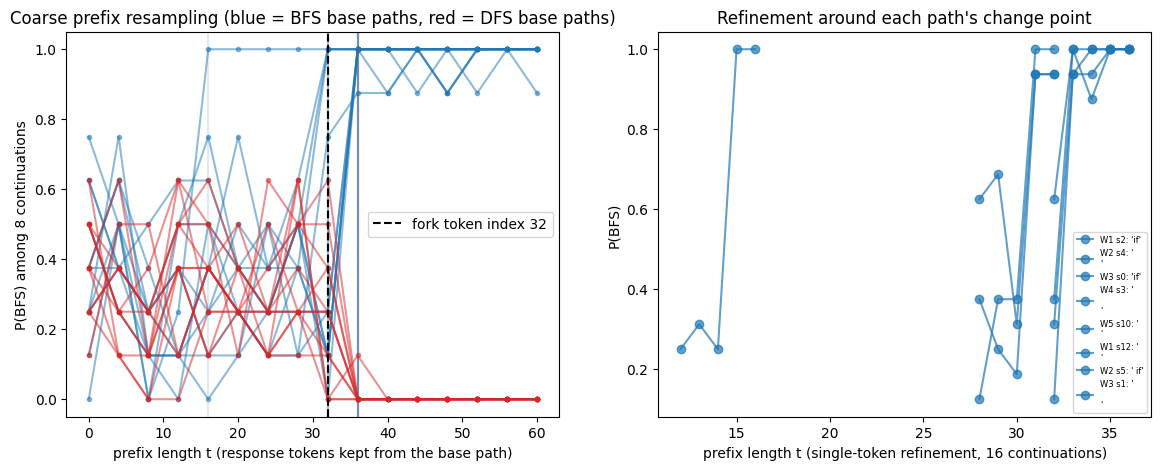

In [20]:
MODE_COL = {"bfs": "#1f77b4", "dfs": "#d62728", "bibfs": "#2ca02c", "iddfs": "#9467bd", "astar_gbfs": "#ff7f0e",
            "dijkstra": "#8c564b"}


def _save(fig: Any, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()                     # notebook: show inline (the script closes the figure: plt.close(fig))


def fork_figure(fk: dict[str, Any]) -> None:
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    for p in fk["per_path"]:
        col = MODE_COL["bfs"] if p["label"] == "bfs" else MODE_COL["dfs"]
        axs[0].plot(p["t"], p["p_bfs"], color=col, alpha=0.5, marker=".")
        if p["fork_t"] is not None:
            axs[0].axvline(p["fork_t"], color=col, alpha=0.15)
    axs[0].axvline(fk["fork_token_index"], color="k", ls="--", label=f"fork token index {fk['fork_token_index']}")
    axs[0].set_xlabel("prefix length t (response tokens kept from the base path)")
    axs[0].set_ylabel("P(BFS) among 8 continuations")
    axs[0].set_title("Coarse prefix resampling (blue = BFS base paths, red = DFS base paths)")
    axs[0].legend()
    for r in fk.get("refined", []):
        ts = [s["t"] for s in r["series"]]
        ps = [s["p_bfs"] for s in r["series"]]
        axs[1].plot(ts, ps, marker="o", color=MODE_COL["bfs"] if r["label"] == "bfs" else MODE_COL["dfs"], alpha=0.7,
                    label=f"{r['row_id'].split('|')[2]} s{r['row_id'].split('|')[-1]}: '{r['fork_token']}'")
    axs[1].set_xlabel("prefix length t (single-token refinement, 16 continuations)")
    axs[1].set_ylabel("P(BFS)")
    axs[1].legend(fontsize=6)
    axs[1].set_title("Refinement around each path's change point")
    _save(fig, "fork_trajectories")


fork_figure(out)

## 11. Results summary: this notebook against the full GPU run

The table compares the S4 numbers computed above (100 samples) with the full run's `results/fork.json` and `results/natural_split.json` (200 samples). Those reference numbers are stored in `metadata.reference_full_run` of the demo data. With the full-run settings, the change-point p-values of all 24 base paths match exactly, because they depend only on a path's own continuations and its fixed seed. The figure shows the decisive next token after c* (left), and where the code reveals the algorithm compared with where the plan is fixed (right).

                                                                 this notebook                    full GPU run
T1 samples: DFS / BFS attempted                                   100: 69 / 31                   200: 139 / 61
pass rate                                                                 0.86                            0.86
U8 partial-labeller agreement                                            1.000                           1.000
BFS base paths with a change point                                       12/12                           12/12
change-point p-values equal to full run                                  24/24                               -
coarse fork position (median)                                               36                              36
global fork token index                                                     32                              32
samples sharing c*                                               90/100 (0.90)                  177/200 (0.89)
B

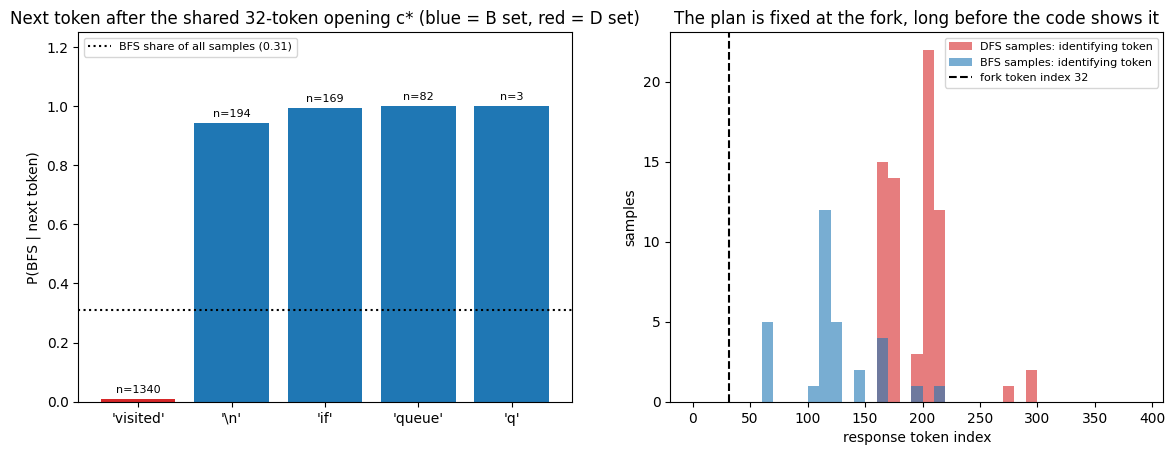

In [21]:
# ---- table: this notebook vs the full GPU run (results/fork.json, results/natural_split.json)
ref = data["metadata"]["reference_full_run"]
rf, rns = ref["fork"], ref["natural_split_T1_all"]
ref_cp = {p["row_id"]: p for p in ref["fork_per_path"]}
n_same_p = sum(1 for p in per_path if p["row_id"] in ref_cp and abs(p["cp"]["p_value"] - ref_cp[p["row_id"]]["cp_p_value"]) < 1e-12)
vis = next((v for v in out["token_table"].values() if v["token"] == "visited"), None)
rvis = ref["fork_token_table_top"].get("visited")
fmt_v = lambda v: "-" if v is None else f"{v['p_bfs']:.3f} (n {v['n']})"  # noqa: E731
summary = [
    ("T1 samples: DFS / BFS attempted", f"{len(rows)}: {comp_t1['attempted'].get('dfs', 0)} / {comp_t1['attempted'].get('bfs', 0)}",
     f"{rns['n']}: {rns['attempted'].get('dfs', 0)} / {rns['attempted'].get('bfs', 0)}"),
    ("pass rate", f"{comp_t1['pass_rate']:.2f}", f"{rns['pass_rate']:.2f}"),
    ("U8 partial-labeller agreement", f"{u8['agreement']:.3f}", f"{rf['U8_partial_labeller']['agreement']:.3f}"),
    ("BFS base paths with a change point",
     f"{sum(p['fork_t'] is not None for p in per_path if p['label'] == 'bfs')}/{sum(p['label'] == 'bfs' for p in per_path)}",
     f"{sum(p['fork_t'] is not None for p in ref['fork_per_path'] if p['label'] == 'bfs')}/12"),
    ("change-point p-values equal to full run", f"{n_same_p}/{len(per_path)}", "-"),
    ("coarse fork position (median)", fork_coarse, rf["fork_coarse_median"]),
    ("global fork token index", tf, rf["fork_token_index"]),
    ("samples sharing c*", f"{cnt}/{len(ids_all)} ({cnt / len(ids_all):.2f})", f"{rf['cstar_count']}/200 ({rf['cstar_share']:.2f})"),
    ("B tokens (-> BFS)", out["B_tokens"], rf["B_tokens"]),
    ("D tokens (-> DFS)", out["D_tokens"], rf["D_tokens"]),
    ("P(BFS | 'visited')", fmt_v(vis), fmt_v(rvis)),
    ("identical-prefix share, mean W1-W5", f"{np.mean(list(ips.values())):.2f}", f"{np.mean(list(rf['identical_prefix_share'].values())):.2f}"),
    ("tokens from fork to identifying token (median)", out["gap_fork_to_identifying"]["median"], rf["gap_fork_to_identifying"]["median"]),
    ("continuations analysed", len(cont), rf["n_continuations"]),
]
w0 = max(len(s[0]) for s in summary)
print(f"{'':{w0}}  {'this notebook':>30}  {'full GPU run':>30}")
for name, x, y in summary:
    print(f"{name:{w0}}  {str(x):>30}  {str(y):>30}")

# ---- figure: the decisive next token after c* (left); fork index vs where the code reveals the algorithm (right)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
tt = sorted([v for v in out["token_table"].values() if not v["pooled"] and v["p_bfs"] is not None], key=lambda v: -v["n"])
cols = [MODE_COL["bfs"] if v["p_bfs"] >= TOKEN_SET_HI else MODE_COL["dfs"] if v["p_bfs"] <= TOKEN_SET_LO else "#7f7f7f" for v in tt]
axs[0].bar(range(len(tt)), [v["p_bfs"] for v in tt], color=cols)
for i, v in enumerate(tt):
    axs[0].text(i, v["p_bfs"] + 0.02, f"n={v['n']}", ha="center", fontsize=8)
axs[0].axhline(u6["s3_bfs_share"], color="k", ls=":", label=f"BFS share of all samples ({u6['s3_bfs_share']:.2f})")
axs[0].set_xticks(range(len(tt)))
axs[0].set_xticklabels([repr(v["token"]) for v in tt])
axs[0].set_ylim(0, 1.25)
axs[0].set_ylabel("P(BFS | next token)")
axs[0].set_title(f"Next token after the shared {tf}-token opening c* (blue = B set, red = D set)")
axs[0].legend(loc="upper left", fontsize=8)
for cls in ("dfs", "bfs"):
    ix = [ident[r["row_id"]]["idx"] for r in valid if F.map_full(r["label"]) == cls and ident[r["row_id"]]["idx"] is not None]
    axs[1].hist(ix, bins=range(0, 400, 10), alpha=0.6, color=MODE_COL[cls], label=f"{cls.upper()} samples: identifying token")
axs[1].axvline(tf, color="k", ls="--", label=f"fork token index {tf}")
axs[1].set_xlabel("response token index")
axs[1].set_ylabel("samples")
axs[1].set_title("The plan is fixed at the fork, long before the code shows it")
axs[1].legend(fontsize=8)
_save(fig, "fork_summary")

## What the GPU stages found at this fork (full run, not re-run here)

Every later stage of experiment 31 reads or pushes the model at the fork position found above. These are the full-run results from the artifact's README; they need the 4B model and the Gemma Scope 2 SAEs on a GPU.

- **Readout.** Over 120 neutral prompt variants (the noun in *"Do not use house …"* swapped), the fork readout y_v varies with SD 0.67 nats and tracks the sampled BFS share (Spearman 0.65). A Lasso on layer-29 SAE codes at the fork position predicts y_v with held-out R² 0.66, against 0.18 for a text-only control. But ridge on the *raw* residual reaches 0.72, and ridge on the SAE codes ≤ 0.09. The information is in the residual stream, and the SAE advantage depends on the estimator. Before the response starts, SAE codes do no better than text (0.18).
- **Steering at the fork** (layer 22, matched edit norm). The change in y is +4.04 nats for difference-in-means (DiM), +1.78 for the SAE clamp, +0.51 for random features and +0.12 for isotropic directions. In generation (N = 50, paired), BFS goes from 13/50 to 30–36/50 with the SAE clamp, 46–49/50 with DiM and 21/50 with random features. Every edit at the fork breaks correctness, though: the pass rate drops from 0.84 to 0.16–0.58, so there is no feature claim. Edits at the task-specification positions do nothing.
- **Prompting.** Banning the five most common algorithms (BFS, DFS, IDDFS, A*, greedy best-first) does not make the model creative. All 50 programs still use a banned algorithm, BFS rises from 10/50 to 41/50 (McNemar 32 vs 1, p = 8e-9), and the pass rate falls to 0.38.
- **Novelty.** 0 novel algorithms among 1,450 correct programs.